# Idea 10 - The Economics of Free

**Machines, Platforms, Crowds, Chapter 7: Paying Complements**

The chapter is a microeconomics tutorial that turns into a strategy argument.
Two goods are complements when a fall in the price of A shifts the demand
curve for B outward. Drive a complement's price to zero and three things
follow: quantity of the free good rises steeply, consumer surplus on it
explodes because every taker captures their full willingness to pay, and the
demand curve for the good you actually sell shifts out. Apple does not pay for
Shazam or Angry Birds; it captures the demand shift from complements the
developers fund.

Consumer surplus is the chapter's key quantity precisely because it appears in
nobody's revenue. That makes it invisible in financial statements and, as this
notebook shows, visible in the national accounts only as an absence.

### What is testable here

1. **The demand curve itself.** Across 398 detailed consumption categories,
   does a larger price fall go with larger growth in quantity? This is the
   chapter's foundational claim, and it can be measured on the whole basket
   rather than asserted from a diagram.
2. **Whether that relationship is real.** A permutation test that shuffles
   quantities against prices says how often a random pairing produces the
   observed slope. Ideas 3 and 7 both turned on a benchmark of this kind.
3. **Surplus invisible in revenue.** If the chapter is right, the categories
   whose prices collapsed should show large quantity growth and flat or
   shrinking revenue. That is a testable and slightly counterintuitive
   prediction about where the money is not.
4. **Two complement pairs, described rather than proved.** Falling equipment
   prices against rising service quantities. Idea 3 showed that a correlation
   between two trending aggregates means nothing without a placebo, and no
   placebo is available for a named pair, so this section is explicitly
   descriptive.

### What is not testable and is not attempted

- **Freemium and cannibalisation.** Needs firm-level pricing and conversion
  data. Nothing in the public accounts distinguishes a free tier.
- **Consumer surplus in dollars.** Idea 4 established that the standard
  constant-elasticity formula returns exactly zero at a zero price, and that
  the answer is otherwise chosen by an unobservable elasticity. Section D
  measures the *shape* of the prediction instead of the level.
- **Two-sided network effects.** Firm-level, not in these data.

In [1]:
import importlib, json, pathlib, shutil, sys, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = None
for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (p / "common" / "stacklib.py").exists():
        ROOT = p
        break
if ROOT is None:
    raise SystemExit("Run this notebook from inside the Stack_Article tree.")
sys.path.insert(0, str(ROOT / "common"))

import stacklib as sl
importlib.reload(sl)
print("stacklib version:", sl.__version__)

DIRS = sl.dirs_for("10_paying_complements", start=ROOT)
KEYS = sl.load_keys()
BEA = sl.require(KEYS, "BEA")

sl.apply_theme()
pd.set_option("display.width", 170)
pd.set_option("display.max_rows", 400)
RNG = np.random.default_rng(20260906)

stacklib version: 0.8.0
Keys loaded from .env: BEA, BLS, CENSUS, FRED


## Data

The same three BEA underlying-detail tables Idea 9 used: price indexes, real
quantity indexes and current-dollar spending, all by type of product. If Idea 9
has already been run its cache is copied across rather than re-downloaded, so
the two notebooks cannot silently diverge onto different vintages.

In [2]:
PRIOR = ROOT / "09_free_perfect_instant" / "data"
for name in ("bea_NIUnderlyingDetail_U20403_A.csv",
             "bea_NIUnderlyingDetail_U20404_A.csv",
             "bea_NIUnderlyingDetail_U20405_A.csv"):
    src, dst = PRIOR / name, pathlib.Path(DIRS["data"]) / name
    if src.exists() and not dst.exists():
        shutil.copyfile(src, dst)
        print("reused Idea 9 cache:", name)

qty = sl.bea_table("NIUnderlyingDetail", "U20403", BEA, cache_dir=DIRS["data"])
px  = sl.bea_table("NIUnderlyingDetail", "U20404", BEA, cache_dir=DIRS["data"])
lvl = sl.bea_table("NIUnderlyingDetail", "U20405", BEA, cache_dir=DIRS["data"])

WIN0, WIN1 = 2000, int(px["year"].max())
print("window: %d to %d" % (WIN0, WIN1))

reused Idea 9 cache: bea_NIUnderlyingDetail_U20403_A.csv
reused Idea 9 cache: bea_NIUnderlyingDetail_U20404_A.csv
reused Idea 9 cache: bea_NIUnderlyingDetail_U20405_A.csv
BEA NIUnderlyingDetail/U20403: reading cache
BEA NIUnderlyingDetail/U20404: reading cache
BEA NIUnderlyingDetail/U20405: reading cache
window: 2000 to 2025


## The estimator, checked first

One statistic carries the whole notebook: the compound annual rate of change
of a series between two years. Plant known answers in constructed series and
confirm it recovers them before pointing it at anything real.

In [3]:
def annual_rate(s, y0=None, y1=None, min_obs=15):
    s = pd.Series(s).dropna()
    if y0 is not None:
        s = s[s.index >= y0]
    if y1 is not None:
        s = s[s.index <= y1]
    s = s[s > 0]
    if len(s) < min_obs:
        return np.nan
    return (s.iloc[-1] / s.iloc[0]) ** (1.0 / (s.index[-1] - s.index[0])) - 1.0

_yrs = np.arange(WIN0, WIN1 + 1)
for planted in (-0.14, -0.02, 0.0, 0.031):
    synth = pd.Series(100 * (1 + planted) ** (_yrs - WIN0), index=_yrs)
    assert abs(annual_rate(synth) - planted) < 1e-9
    print("planted %+.3f recovered %+.9f  ok" % (planted, annual_rate(synth)))

def series_by_line(tidy):
    """line -> (description, Series indexed by year)."""
    out = {}
    for line_no, g in tidy.groupby("line"):
        s = g.drop_duplicates(subset=["year"]).set_index("year")["value"].sort_index()
        out[int(line_no)] = (str(g["description"].iloc[0]).strip(), s)
    return out

PX, QY, LV = series_by_line(px), series_by_line(qty), series_by_line(lvl)
print("\nlines: price %d, quantity %d, spending %d" % (len(PX), len(QY), len(LV)))

planted -0.140 recovered -0.140000000  ok
planted -0.020 recovered -0.020000000  ok
planted +0.000 recovered +0.000000000  ok
planted +0.031 recovered +0.031000000  ok

lines: price 400, quantity 400, spending 402


## Section A - the demand curve, measured on the whole basket

For every category that appears in both the price and quantity tables, the
annualised price change and the annualised real quantity change over the same
window. If the chapter's foundational claim holds, the cloud slopes downward:
categories whose prices fell furthest are the ones people took most of.

Aggregate lines are dropped. BEA's tables mix totals with their own components,
and leaving both in would count the same spending several times and pull the
fit toward the aggregates.

In [4]:
import re as _re
AGG_PAT = _re.compile(
    r"^(personal consumption expenditures|pce\b|market-based|goods$|services$|"
    r"durable goods|nondurable goods|less:|addenda|total\b|final consumption)", _re.I)

rows = []
for line_no, (desc, sp) in PX.items():
    if line_no not in QY:
        continue
    _, sq = QY[line_no]
    rp, rq = annual_rate(sp, WIN0, WIN1), annual_rate(sq, WIN0, WIN1)
    if np.isfinite(rp) and np.isfinite(rq):
        rows.append({"line": line_no, "description": desc,
                     "price": rp * 100, "quantity": rq * 100,
                     "aggregate": bool(AGG_PAT.search(desc))})

D = pd.DataFrame(rows).set_index("line")
print("matched %d categories; %d flagged as aggregates and excluded from the fit"
      % (len(D), int(D["aggregate"].sum())))
DF = D[~D["aggregate"]].copy()

print("\nexcluded as aggregates:")
for d in sorted(D[D["aggregate"]]["description"])[:20]:
    print("   " + d)

slope, intercept = np.polyfit(DF["price"], DF["quantity"], 1)
r = float(np.corrcoef(DF["price"], DF["quantity"])[0, 1])
print("\nfit on %d categories:  quantity = %.3f x price %+0.2f      r = %.3f"
      % (len(DF), slope, intercept, r))
print("reading: one point a year less price growth goes with %.2f points a year "
      "more quantity growth" % (-slope))

matched 398 categories; 43 flagged as aggregates and excluded from the fit

excluded as aggregates:
   Durable goods
   Final consumption expenditures of nonprofit institutions serving households (NPISHs) (132)
   Goods
   Less: Expenditures in the United States by nonresidents (130)
   Less: Household insurance normal losses
   Less: Personal remittances in kind to nonresidents
   Less: Receipts from sales of goods and services by nonprofit institutions (134)
   Market-based PCE
   Market-based PCE child care
   Market-based PCE clothing and footwear
   Market-based PCE communication services
   Market-based PCE durable goods other than motor vehicles and parts
   Market-based PCE education
   Market-based PCE excluding energy
   Market-based PCE excluding food
   Market-based PCE excluding food and energy
   Market-based PCE financial services and insurance
   Market-based PCE food and beverages purchased for off-premises consumption
   Market-based PCE food and energy
   Market-base

### The double-counting problem, and whether it matters

BEA's detail table is a hierarchy. "Information processing equipment" appears
as its own line and so do the personal computers inside it, so a fast-falling
family enters the cloud several times and pulls the fit toward itself. The
aggregate filter above catches the named totals and not these intermediate
subtotals.

Three checks. Drop every line whose components are also present, score the
rank correlation, which does not care how far an outlier sits from the line,
and bootstrap the slope. If the result is an artefact of duplicated families,
it will not survive all three.

In [5]:
SUBTOTALS = [
    r"^information processing equipment$",
    r"^video and audio equipment$",
    r"^video, audio, photographic, and information processing",
    r"^recreational goods and vehicles$",
    r"^furnishings and durable household equipment$",
    r"^other durable goods$",
    r"^household consumption expenditures",
    r"^final consumption expenditures",
]
is_sub = DF["description"].str.contains("|".join(SUBTOTALS), case=False,
                                        regex=True, na=False)
print("intermediate subtotals dropped for the robustness fit (%d):" % int(is_sub.sum()))
for d in DF[is_sub]["description"]:
    print("   " + d)

LEAF = DF[~is_sub]
slope_leaf = float(np.polyfit(LEAF["price"], LEAF["quantity"], 1)[0])

try:
    from scipy.stats import spearmanr
    rho, rho_p = spearmanr(DF["price"], DF["quantity"])
except ImportError:                      # rank correlation without scipy
    rho = float(DF["price"].rank().corr(DF["quantity"].rank()))
    rho_p = float("nan")
    print("scipy unavailable; rank correlation computed without a p-value.")

boot = np.empty(1000)
idx = np.arange(len(DF))
for i in range(len(boot)):
    take = RNG.choice(idx, size=len(idx), replace=True)
    boot[i] = np.polyfit(DF["price"].to_numpy()[take],
                         DF["quantity"].to_numpy()[take], 1)[0]
lo, hi = np.percentile(boot, [2.5, 97.5])

print("\n  slope, all %d categories        %.3f" % (len(DF), slope))
print("  slope, %d after dropping subtotals  %.3f" % (len(LEAF), slope_leaf))
print("  bootstrap 95%% interval            %.3f to %.3f" % (lo, hi))
print("  Spearman rank correlation         %.3f  (p = %.2g)" % (rho, rho_p))

intermediate subtotals dropped for the robustness fit (7):
   Furnishings and durable household equipment
   Recreational goods and vehicles
   Video, audio, photographic, and information processing equipment and media (75, 76, and part of 93)
   Video and audio equipment
   Information processing equipment
   Other durable goods
   Household consumption expenditures (for services)

  slope, all 355 categories        -0.882
  slope, 348 after dropping subtotals  -0.838
  bootstrap 95% interval            -1.048 to -0.665
  Spearman rank correlation         -0.518  (p = 8.7e-26)


## Section B - is that slope real?

A downward-sloping cloud is what the theory predicts, and it is also what you
get from any two variables that share a common trend. Shuffle the quantity
growth rates against the price growth rates two thousand times and see how
often chance produces a slope this steep. This is the test that overturned the
power-law reading in Idea 7, applied here to a result that is congenial.

observed |slope| 0.882    permuted mean 0.055    p = 0.0000
saved -> C:\Users\91838\Downloads\Stack_Article\10_paying_complements\figures\fig1_permutation_slope.png


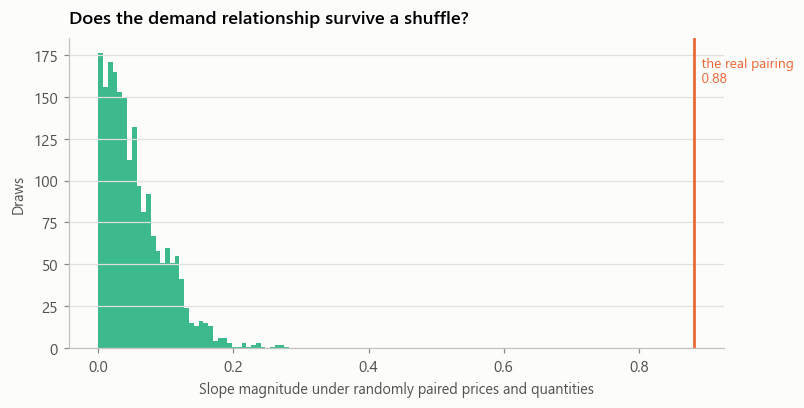

In [6]:
N_PERM = 2000
obs = abs(slope)
null = np.empty(N_PERM)
q = DF["quantity"].to_numpy()
p = DF["price"].to_numpy()
for i in range(N_PERM):
    null[i] = abs(np.polyfit(p, RNG.permutation(q), 1)[0])
p_val = float((null >= obs).mean())
print("observed |slope| %.3f    permuted mean %.3f    p = %.4f"
      % (obs, null.mean(), p_val))

fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.hist(null, bins=40, color=sl.PALETTE[2], alpha=0.85, lw=0)
ax.axvline(obs, color=sl.PALETTE[1], lw=1.8)
ax.text(obs, ax.get_ylim()[1] * 0.94, "  the real pairing\n  %.2f" % obs,
        color=sl.PALETTE[1], fontsize=9, va="top", ha="left")
ax.set_xlabel("Slope magnitude under randomly paired prices and quantities")
ax.set_ylabel("Draws")
ax.set_title("Does the demand relationship survive a shuffle?")
sl.save_fig(fig, "fig1_permutation_slope", DIRS)
plt.show()

saved -> C:\Users\91838\Downloads\Stack_Article\10_paying_complements\figures\fig2_price_vs_quantity.png


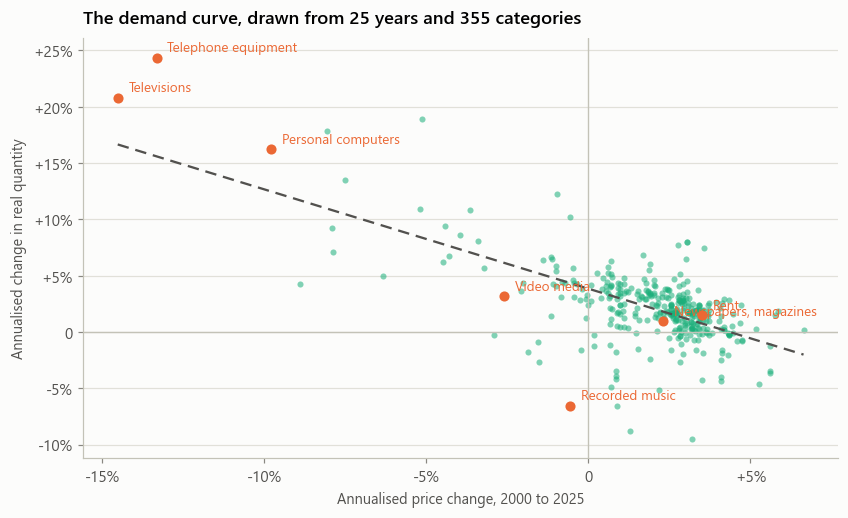

In [7]:
MARK = {
    "Personal computers": r"personal computers/tablets",
    "Telephone equipment": r"^telephone and related communication equipment",
    "Televisions": r"^televisions$",
    "Video media": r"video discs, tapes",
    "Recorded music": r"audio discs, tapes",
    "Newspapers, magazines": r"magazines, newspapers, and stationery",
    "Rent": r"rental of tenant-occupied nonfarm",
}
picks = {}
for label, pat in MARK.items():
    m = DF[DF["description"].str.contains(pat, case=False, regex=True, na=False)]
    if len(m):
        picks[label] = m.iloc[0]
    else:
        print("WARNING  no category matched %r for %s" % (pat, label))

fig, ax = plt.subplots(figsize=(7.6, 4.6))
ax.scatter(DF["price"], DF["quantity"], s=16, color=sl.PALETTE[2],
           alpha=0.55, lw=0, zorder=2)
xs = np.linspace(DF["price"].min(), DF["price"].max(), 50)
ax.plot(xs, slope * xs + intercept, color=sl.INK["secondary"], lw=1.5,
        ls=(0, (5, 3)), zorder=3)
for label, row in picks.items():
    ax.scatter([row["price"]], [row["quantity"]], s=44, color=sl.PALETTE[1],
               zorder=4, lw=0)
    ax.annotate(label, (row["price"], row["quantity"]),
                textcoords="offset points", xytext=(7, 4),
                color=sl.PALETTE[1], fontsize=8.8, zorder=5)
ax.axhline(0, color=sl.INK["axis"], lw=0.9)
ax.axvline(0, color=sl.INK["axis"], lw=0.9)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: ("%+d%%" % v) if v else "0"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: ("%+d%%" % v) if v else "0"))
ax.set_xlabel("Annualised price change, %d to %d" % (WIN0, WIN1))
ax.set_ylabel("Annualised change in real quantity")
ax.set_title("The demand curve, drawn from 25 years and %d categories" % len(DF))
sl.save_fig(fig, "fig2_price_vs_quantity", DIRS)
plt.show()

## Section C - where the surplus goes, and why nobody books it

Consumer surplus does not appear in revenue, so a category can deliver far
more to buyers while the industry serving it takes a smaller share of
spending. That is the chapter's claim about invisibility, and it is testable:
take the categories whose prices collapsed and ask what happened to their
share of the consumption dollar.

In [8]:
COLLAPSED = DF[DF["price"] <= -3.0].copy()
share_now, share_then = {}, {}
tot_line = None
for line_no, (desc, s) in LV.items():
    if desc.strip().lower() == "personal consumption expenditures":
        tot_line = line_no
        break
if tot_line is None:
    raise LookupError("Total PCE line not found in the spending table.")
TOT = LV[tot_line][1]

for line_no in COLLAPSED.index:
    if line_no not in LV:
        continue
    s = LV[line_no][1]
    both = s.index.intersection(TOT.index)
    sh = (s.reindex(both) / TOT.reindex(both)) * 10000
    if WIN0 in sh.index and WIN1 in sh.index and np.isfinite(sh.loc[WIN0]):
        share_then[line_no] = float(sh.loc[WIN0])
        share_now[line_no] = float(sh.loc[WIN1])

C = COLLAPSED.loc[list(share_now)].assign(
    share_2000=pd.Series(share_then), share_last=pd.Series(share_now))
C["share_change_pct"] = (C["share_last"] / C["share_2000"] - 1) * 100
C = C.sort_values("price")
print("categories whose price fell at least 3%% a year (%d of %d):" % (len(C), len(DF)))
print(C[["description", "price", "quantity", "share_2000", "share_last",
         "share_change_pct"]].round(1).to_string())
print("\nshare of the consumption dollar fell in %d of %d of them"
      % (int((C["share_change_pct"] < 0).sum()), len(C)))

categories whose price fell at least 3% a year (18 of 355):
                                                                                              description  price  quantity  share_2000  share_last  share_change_pct
line                                                                                                                                                                
41                                                                                            Televisions  -14.5      20.8        23.3        16.8             -27.8
71                                                          Telephone and related communication equipment  -13.3      24.4         8.1        17.2             111.4
49                                                    Personal computers/tablets and peripheral equipment   -9.8      16.2        46.8        49.5               5.8
51                                   Calculators, typewriters, and other information processing equipment   -8.9   

saved -> C:\Users\91838\Downloads\Stack_Article\10_paying_complements\figures\fig3_share_of_spending.png


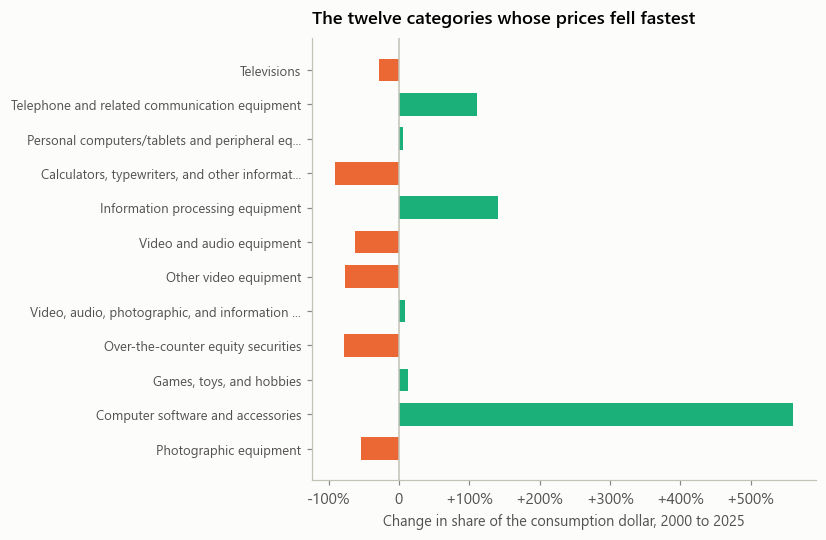

In [9]:
top = C.nsmallest(12, "price").iloc[::-1]
ypos = np.arange(len(top))
fig, ax = plt.subplots(figsize=(7.4, 4.8))
ax.barh(ypos, top["share_change_pct"], color=[
    sl.PALETTE[1] if v < 0 else sl.PALETTE[2] for v in top["share_change_pct"]],
    height=0.66, lw=0)
ax.set_yticks(ypos)
ax.set_yticklabels([d if len(d) < 46 else d[:44] + "..." for d in top["description"]],
                   fontsize=8.6)
ax.axvline(0, color=sl.INK["axis"], lw=1.0)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: ("%+d%%" % v) if v else "0"))
ax.set_xlabel("Change in share of the consumption dollar, %d to %d" % (WIN0, WIN1))
ax.set_title("The twelve categories whose prices fell fastest")
ax.grid(axis="y", visible=False)
sl.save_fig(fig, "fig3_share_of_spending", DIRS)
plt.show()

## Section D - the surplus diagram, and the complement shift

Arithmetic, not evidence, and the write-up should say so. The chapter's
mechanism is geometric and the geometry is worth drawing once: revenue is the
rectangle under the equilibrium point, surplus is the triangle above the price
line and below the demand curve, and a complement going free shifts the whole
curve outward rather than moving along it.

The elasticity is a choice, so the panel reports the surplus it implies rather
than claiming a number. Idea 4 covers why that choice cannot be settled.

saved -> C:\Users\91838\Downloads\Stack_Article\10_paying_complements\figures\fig4_surplus_geometry.png


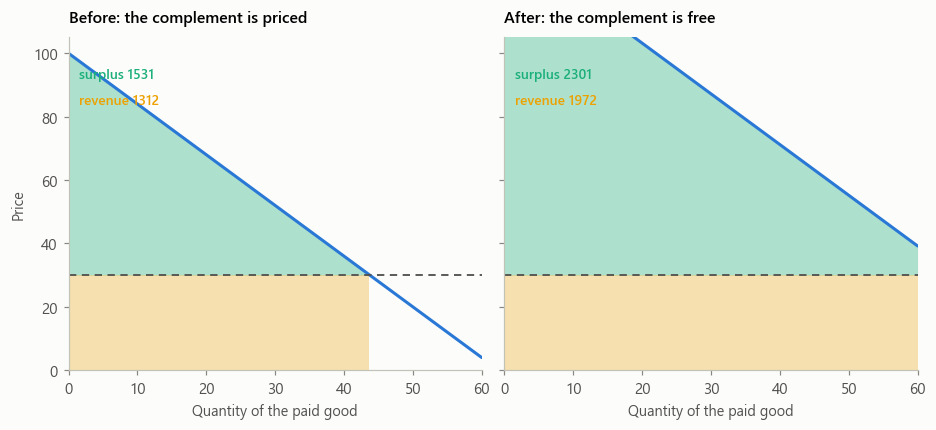

In [10]:
def demand(q, a=100.0, b=1.6):
    return np.maximum(a - b * q, 0.0)

Q = np.linspace(0, 60, 400)
P_STAR, SHIFT = 30.0, 22.0

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.8), sharey=True)
for ax, shift, title in zip(axes, [0.0, SHIFT],
                            ["Before: the complement is priced",
                             "After: the complement is free"]):
    d = demand(Q - shift)
    ax.plot(Q, d, color=sl.PALETTE[0], lw=2.0)
    q_star = (100.0 - P_STAR) / 1.6 + shift
    ax.axhline(P_STAR, color=sl.INK["secondary"], lw=1.2, ls=(0, (4, 3)))
    ax.fill_between(Q[Q <= q_star], P_STAR, demand(Q[Q <= q_star] - shift),
                    color=sl.PALETTE[2], alpha=0.35, lw=0)
    ax.fill_between(Q[Q <= q_star], 0, P_STAR, color=sl.PALETTE[3], alpha=0.30, lw=0)
    surplus = 0.5 * q_star * (demand(np.array([shift]) - shift)[0] - P_STAR)
    ax.text(1.5, 92, "surplus %.0f" % surplus, color=sl.PALETTE[2],
            fontsize=9, fontweight="semibold")
    ax.text(1.5, 84, "revenue %.0f" % (P_STAR * q_star), color=sl.PALETTE[3],
            fontsize=9, fontweight="semibold")
    ax.set_xlim(0, 60)
    ax.set_ylim(0, 105)
    ax.set_xlabel("Quantity of the paid good")
    ax.set_title(title, fontsize=10.5)
    ax.grid(visible=False)
axes[0].set_ylabel("Price")
sl.save_fig(fig, "fig4_surplus_geometry", DIRS)
plt.show()

## Section E - two complement pairs, described

Equipment prices against the quantity of the service the equipment is bought
to use. Idea 3 showed that two trending aggregates produce a respectable
correlation for no reason at all, and there is no placebo available for a
named pair, so this section describes and does not infer.

Telephone equipment and cellular service
   price:    Telephone and related communication equipment
   quantity: Telecommunication services (71)
Computers and internet access
   price:    Personal computers/tablets and peripheral equipment
   quantity: Internet access (72)
saved -> C:\Users\91838\Downloads\Stack_Article\10_paying_complements\figures\fig5_complement_pairs.png


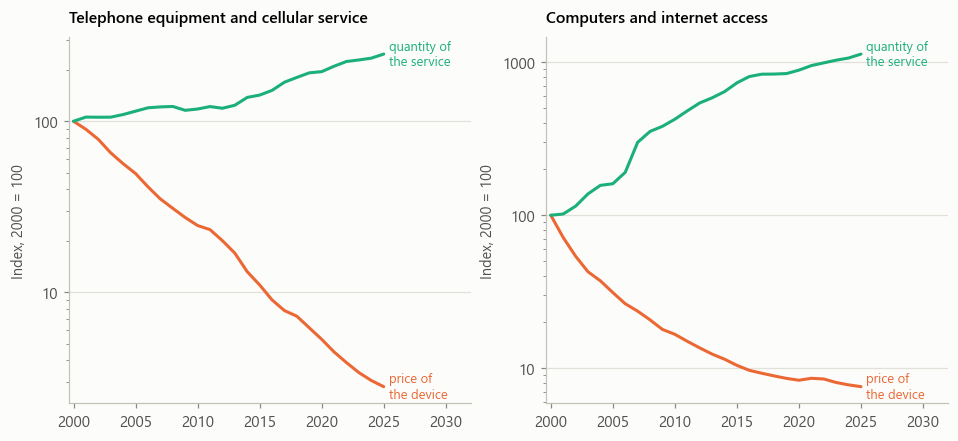

In [11]:
PAIRS = [
    ("Telephone equipment and cellular service",
     r"^telephone and related communication equipment",
     r"cellular telephone services|telecommunication services"),
    ("Computers and internet access",
     r"personal computers/tablets",
     r"internet access|data processing"),
]

def find_line(store, pat):
    for line_no, (desc, s) in store.items():
        if _re.search(pat, desc, _re.I):
            return line_no, desc, s
    return None

fig, axes = plt.subplots(1, len(PAIRS), figsize=(8.6, 3.9))
pair_out = {}
for ax, (title, pat_px, pat_qy) in zip(np.atleast_1d(axes), PAIRS):
    a = find_line(PX, pat_px)
    b = find_line(QY, pat_qy)
    if a is None or b is None:
        ax.text(0.5, 0.5, "series not found", ha="center", va="center",
                transform=ax.transAxes, color=sl.INK["muted"])
        ax.set_title(title, fontsize=10.5)
        print("WARNING  %s: price=%s quantity=%s" % (title, bool(a), bool(b)))
        continue
    _, da, sa = a
    _, db, sb = b
    yrs = sa.index.intersection(sb.index)
    yrs = yrs[(yrs >= WIN0) & (yrs <= WIN1)]
    A = sa.reindex(yrs) / sa.reindex(yrs).iloc[0] * 100
    B = sb.reindex(yrs) / sb.reindex(yrs).iloc[0] * 100
    ax.plot(yrs, A.values, color=sl.PALETTE[1], lw=2.0)
    ax.plot(yrs, B.values, color=sl.PALETTE[2], lw=2.0)
    ax.text(yrs[-1] + 0.4, A.iloc[-1], "price of\nthe device", color=sl.PALETTE[1],
            fontsize=8.5, va="center", linespacing=1.25)
    ax.text(yrs[-1] + 0.4, B.iloc[-1], "quantity of\nthe service", color=sl.PALETTE[2],
            fontsize=8.5, va="center", linespacing=1.25)
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%g" % v))
    ax.set_xlim(yrs[0] - 0.4, yrs[-1] + 7)
    ax.set_title(title, fontsize=10.5)
    ax.set_ylabel("Index, %d = 100" % WIN0)
    pair_out[title] = {"price_line": da, "quantity_line": db,
                       "price_rate": annual_rate(sa, WIN0, WIN1),
                       "quantity_rate": annual_rate(sb, WIN0, WIN1)}
    print("%s\n   price:    %s\n   quantity: %s" % (title, da, db))
sl.save_fig(fig, "fig5_complement_pairs", DIRS)
plt.show()

## Payload

In [12]:
payload = {
    "window": [WIN0, WIN1],
    "demand": {
        "n_categories": int(len(DF)),
        "n_aggregates_excluded": int(D["aggregate"].sum()),
        "slope": float(slope),
        "intercept": float(intercept),
        "correlation": r,
        "slope_excluding_subtotals": slope_leaf,
        "n_excluding_subtotals": int(len(LEAF)),
        "bootstrap_ci": [float(lo), float(hi)],
        "spearman_rho": float(rho),
        "spearman_p": float(rho_p),
        "permutation_p": p_val,
        "permutation_draws": N_PERM,
        "permuted_mean_abs_slope": float(null.mean()),
    },
    "collapsed": {
        "threshold_pct_per_year": -3.0,
        "n": int(len(C)),
        "n_losing_share": int((C["share_change_pct"] < 0).sum()),
        "median_quantity_growth": float(C["quantity"].median()),
        "median_share_change_pct": float(C["share_change_pct"].median()),
        "table": C[["description", "price", "quantity", "share_2000",
                    "share_last", "share_change_pct"]].round(3)
                  .to_dict(orient="records"),
    },
    "marked_categories": {k: {"description": v["description"],
                              "price": float(v["price"]),
                              "quantity": float(v["quantity"])}
                          for k, v in picks.items()},
    "complement_pairs": {k: {kk: (float(vv) if isinstance(vv, float) else vv)
                             for kk, vv in v.items()} for k, v in pair_out.items()},
}
sl.write_findings(payload, DIRS)

DF.to_csv(pathlib.Path(DIRS["findings"]) / "price_vs_quantity.csv")
C.to_csv(pathlib.Path(DIRS["findings"]) / "collapsed_categories.csv")
print(json.dumps({k: v for k, v in payload.items() if k != "collapsed"}, indent=2)[:2200])

findings -> C:\Users\91838\Downloads\Stack_Article\10_paying_complements\findings\headline_numbers.json
{
  "window": [
    2000,
    2025
  ],
  "demand": {
    "n_categories": 355,
    "n_aggregates_excluded": 43,
    "slope": -0.8817909125990854,
    "intercept": 3.848768193423476,
    "correlation": -0.6562124808604213,
    "slope_excluding_subtotals": -0.8376609208084231,
    "n_excluding_subtotals": 348,
    "bootstrap_ci": [
      -1.047623997062209,
      -0.664897439829027
    ],
    "spearman_rho": -0.5182142813795729,
    "spearman_p": 8.688991913418667e-26,
    "permutation_p": 0.0,
    "permutation_draws": 2000,
    "permuted_mean_abs_slope": 0.055345815272980756
  },
  "marked_categories": {
    "Personal computers": {
      "description": "Personal computers/tablets and peripheral equipment",
      "price": -9.792997560587924,
      "quantity": 16.247615191704234
    },
    "Telephone equipment": {
      "description": "Telephone and related communication equipment",
   

## What to send back

The five PNGs in `figures/`, `findings/headline_numbers.json`, and the printed
table of collapsed categories. If any WARNING appeared in Section E or in the
`MARK` block, send the surrounding output too and the patterns can be
re-pointed without rerunning the notebook.